# Calibração dos limiares do Avaliador Híbrido

Objetivo: ver como as métricas **determinísticas** (Flesch PT, densidade de termos, % de palavras longas)
se distribuem por nível e propor cortes entre os grupos. Os cortes finais vão para
`backend/evaluator/thresholds.yaml` só depois de revisados.

**Fontes de dados, em ordem de prioridade**
1. `data/processed/*.json`: documentos-fonte (ata, fato relevante, release) = referência de **avançado**.
2. `data/reference/<nivel>/*.txt|md`: textos humanos de referência por nível.
3. Saídas do pipeline em `outputs/<doc>/` (rótulo = nível-alvo).
4. *Fallback:* textos golden de `tests/fixtures/golden/` (poucos, escritos à mão; só ilustram o método).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from backend.evaluator.glossary import TermMatcher, load_glossary
from backend.evaluator.readability import readability, textstat_flesch_pt
from backend.evaluator.term_density import term_density
from backend.evaluator.thresholds import load_thresholds
from backend.schemas import Audience, SourceDocument
from backend.experiments.evaluate import latest_run

matcher = TermMatcher(load_glossary())
LEVELS = [a.value for a in Audience]

In [2]:
samples = []  # (origem, nível, texto)

for p in sorted((ROOT / "data/processed").glob("*.json")):
    samples.append(("fonte", "avancado", SourceDocument.model_validate_json(p.read_text()).text))

for level in LEVELS:
    for p in sorted((ROOT / "data/reference" / level).glob("*")):
        if p.suffix in {".txt", ".md"}:
            samples.append(("referencia", level, p.read_text()))

for d in sorted((ROOT / "outputs").glob("*")):
    if d.is_dir() and d.name != "reports" and (run := latest_run(d.name)):
        for out in run.state.outputs.values():
            samples.append(("pipeline", out.audience.value, out.plain_text()))

GOLDEN = {"iniciante_bom": "iniciante", "iniciante_numero_inventado": "iniciante",
          "intermediario_bom": "intermediario", "intermediario_hiato": "intermediario",
          "avancado_bom": "avancado", "copom_trecho": "avancado", "fonte_copom": "avancado"}
using_fallback = not samples
if using_fallback:
    for name, level in GOLDEN.items():
        samples.append(("golden", level, (ROOT / "tests/fixtures/golden" / f"{name}.txt").read_text()))

print(f"{len(samples)} textos | fallback golden: {using_fallback}")
pd.Series([f"{o}/{l}" for o, l, _ in samples]).value_counts()

7 textos | fallback golden: True


golden/avancado         3
golden/iniciante        2
golden/intermediario    2
Name: count, dtype: int64

## Métricas por texto

A densidade é calculada sem depender do nível-alvo (conta todos os termos do glossário).
`flesch_textstat` é a referência externa (textstat, `lang="pt"`), só para comparação.

In [3]:
rows = []
for origin, level, text in samples:
    r = readability(text)
    td = term_density(text, Audience(level), matcher)
    rows.append({"origem": origin, "nivel": level, "palavras": r.words, "flesch_pt": r.flesch_pt,
                 "flesch_textstat": textstat_flesch_pt(text), "palavras_por_frase": r.words_per_sentence,
                 "pct_4mais_silabas": r.pct_polysyllables, "term_density": td.density, "context_pct": td.context_pct})
df = pd.DataFrame(rows)
df["nivel"] = pd.Categorical(df.nivel, LEVELS, ordered=True)
df.sort_values("nivel").round(2)

,origem,nivel,palavras,flesch_pt,flesch_textstat,palavras_por_frase,pct_4mais_silabas,term_density,context_pct
0,golden,iniciante,132,88.85,52.97,10.15,3.85,0.76,100.0
1,golden,iniciante,62,90.30,55.80,10.33,3.33,1.61,100.0
2,golden,intermediario,113,50.43,22.26,18.83,14.68,7.96,100.0
3,golden,intermediario,113,59.74,27.50,18.83,9.17,5.31,0.0
4,golden,avancado,138,21.84,0.32,34.50,20.00,10.14,100.0
5,golden,avancado,109,16.83,-13.21,21.80,28.85,8.26,100.0
6,golden,avancado,168,27.99,0.56,21.00,23.90,7.14,100.0


## Flesch próprio × textstat

**O textstat não tem configuração para português.** Com `set_lang("pt")` ele usa os coeficientes do inglês
(base **206,835**), não os de Martins et al. (**248,835**). Só a constante já explica ~42 pontos a menos.
Na contagem, o textstat usa pyphen com `left/right=2` (junta sílabas de uma letra: "água" = 1) e conta
números como palavras; isso dá um pouco menos sílabas por palavra e compensa parte da diferença.
Resultado: o textstat fica uns 30 pontos abaixo da nossa implementação. Usar o textstat com os limiares
de Martins (≥ 60 para iniciante) reprovaria quase todo texto. A métrica oficial é `flesch_pt`.

In [4]:
diff = (df.flesch_pt - df.flesch_textstat)
print(f"diferença média (nosso - textstat): {diff.mean():.1f} pontos | desvio: {diff.std():.1f}")
df[["nivel", "flesch_pt", "flesch_textstat"]].assign(diferenca=diff.round(1))

diferença média (nosso - textstat): 30.0 pontos | desvio: 4.9


,nivel,flesch_pt,flesch_textstat,diferenca
0,iniciante,88.85,52.97,35.9
1,iniciante,90.30,55.80,34.5
2,intermediario,50.43,22.26,28.2
3,intermediario,59.74,27.50,32.2
4,avancado,21.84,0.32,21.5
5,avancado,16.83,-13.21,30.0
6,avancado,27.99,0.56,27.4


## Distribuição por nível

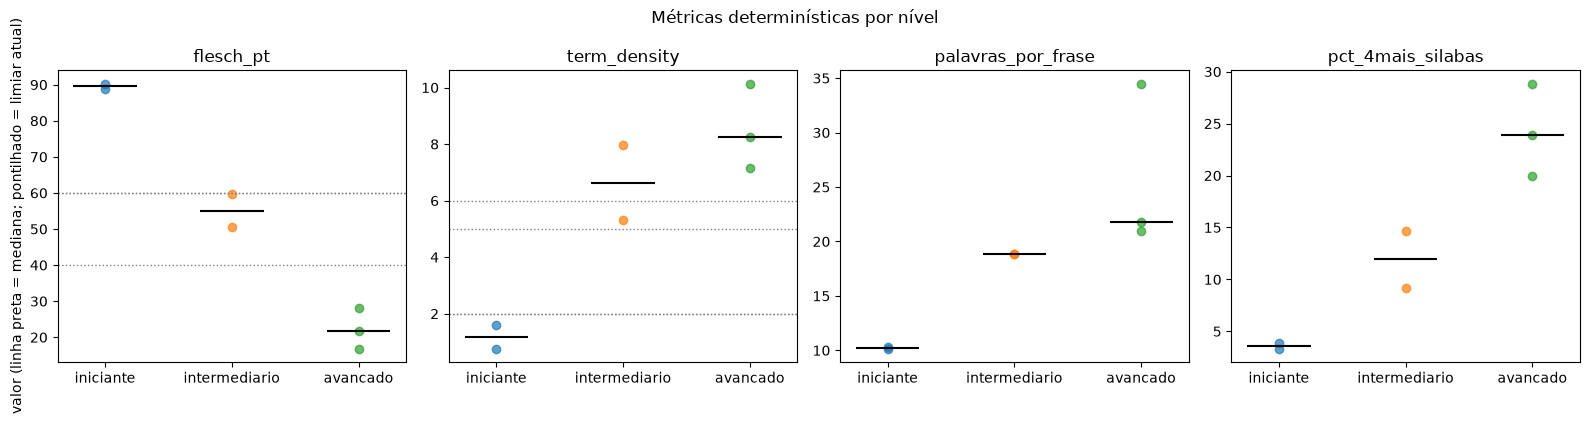

In [5]:
metrics = ["flesch_pt", "term_density", "palavras_por_frase", "pct_4mais_silabas"]
fig, axes = plt.subplots(1, len(metrics), figsize=(16, 4))
th = load_thresholds()
for ax, m in zip(axes, metrics):
    for i, level in enumerate(LEVELS):
        vals = df[df.nivel == level][m]
        ax.scatter([i] * len(vals), vals, alpha=0.7)
        if len(vals):
            ax.hlines(vals.median(), i - 0.25, i + 0.25, color="black")
    if m in ("flesch_pt", "term_density"):
        for level in LEVELS:
            b = th.level_bound(Audience(level), m)
            for v in (b.min, b.max):
                if v is not None:
                    ax.axhline(v, ls=":", lw=1, color="gray")
    ax.set_xticks(range(3), LEVELS)
    ax.set_title(m)
axes[0].set_ylabel("valor (linha preta = mediana; pontilhado = limiar atual)")
fig.suptitle("Métricas determinísticas por nível")
fig.tight_layout()

## Cortes propostos

Método: para cada métrica, o corte entre dois níveis vizinhos é o ponto médio entre as medianas dos grupos.
Com poucos textos por nível o ponto médio é instável; nesse caso o corte proposto **não** substitui o
limiar do briefing, só indica a direção do ajuste.

In [6]:
med = df.groupby("nivel", observed=False)[["flesch_pt", "term_density"]].median()
proposals = {}
for m in ["flesch_pt", "term_density"]:
    a, b, c = (med.loc[l, m] for l in LEVELS)
    proposals[m] = {"iniciante|intermediario": round((a + b) / 2, 1), "intermediario|avancado": round((b + c) / 2, 1)}
counts = df.nivel.value_counts().reindex(LEVELS)
print("n por nível:", counts.to_dict())
print("medianas:\n", med.round(2))
print("cortes (ponto médio das medianas):", proposals)

n por nível: {'iniciante': 2, 'intermediario': 2, 'avancado': 3}
medianas:
                flesch_pt  term_density
nivel                                 
iniciante          89.57          1.18
intermediario      55.08          6.64
avancado           21.84          8.26
cortes (ponto médio das medianas): {'flesch_pt': {'iniciante|intermediario': np.float64(72.3), 'intermediario|avancado': np.float64(38.5)}, 'term_density': {'iniciante|intermediario': np.float64(3.9), 'intermediario|avancado': np.float64(7.4)}}


## Justificativa e decisão

**Leitura dos dados atuais.** Se a célula acima mostrar `fallback golden: True`, os números vêm de 7 textos
escritos à mão e servem só para validar o método. Com esses textos já aparecem dois sinais:

1. **Flesch separa bem os três grupos.** Iniciante ~89, intermediário 50–60, textos no estilo ata 17–28.
   O corte de **60 para iniciante** tem folga dos dois lados e fica; a faixa **40–60** do intermediário
   também cobre os dois textos (o de 59,7 está no limite: vale reavaliar com dados reais).
2. **Densidade do intermediário.** Um texto intermediário bem escrito usa Selic, CDI, IPCA, Copom e dividendos
   quase em toda frase e chega a 8 termos por 100 palavras. O teto de **6** do briefing reprova esse texto e
   empurra o classificador para "avançado". Proposta a confirmar com dados reais: intermediário em **2–8** e
   avançado **≥ 7** (o ponto médio das medianas deu 7,4).
3. **A densidade mínima do avançado pega a trivialização:** o texto avançado sem jargão ficou em 0.

**Decisão para o thresholds.yaml hoje:** manter os valores do briefing. Os ajustes do item 2 entram só depois
de rodar este notebook com os 3 PDFs, as saídas do pipeline e pelo menos ~5 textos de referência por nível.
Critério para aceitar um corte: separar as medianas vizinhas sem cruzar mais de 20% dos textos de referência
de cada lado.